# MicroGrad — Assignment 1 Demo Notebook

**Course:** CSE485–CSE488 Deep Learning  
**Assignment:** MicroGrad (Scalar Autograd Engine)

This notebook demonstrates the implementation in `src/engine.py` and `src/nn.py`.

> **How to run:** Save this notebook in the root folder of the cloned assignment repository (the same folder that contains `src/`). Run the cells from top to bottom. The notebook uses the assignment implementation; it does not reimplement the engine here.


## 1. Environment and imports

We import the `Value` class and neural-network classes from the project source code. The notebook should be run from the repository root so that `src` is importable.


In [1]:
import sys
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt

# Confirm that the notebook is running from the repository root.
print("Working directory:", Path.cwd())
print("src folder exists:", Path("src").exists())

from src.engine import Value
from src.nn import Neuron, Layer, MLP

random.seed(42)
print("Imports successful.")


Working directory: c:\term7\deep\assigment1\assignment-1-micrograd-template
src folder exists: True
Imports successful.


## 2. Test scalar operations (forward pass)

`Value` stores a scalar in `.data`. Arithmetic operations create new `Value` objects and retain links to their input nodes in `._prev`.


In [2]:
a = Value(2.0, label="a")
b = Value(3.0, label="b")

addition = a + b
multiplication = a * b
power = a ** 3
division = Value(6.0) / Value(2.0)

print("a + b =", addition.data)
print("a * b =", multiplication.data)
print("a ** 3 =", power.data)
print("6 / 2 =", division.data)


a + b = 5.0
a * b = 6.0
a ** 3 = 8.0
6 / 2 = 3.0


## 3. Activation functions

The engine implements hyperbolic tangent (`tanh`) and the exponential function (`exp`).


In [3]:
x_tanh = Value(0.5)
x_exp = Value(1.0)

print("tanh(0.5) =", x_tanh.tanh().data)
print("exp(1.0)  =", x_exp.exp().data)


tanh(0.5) = 0.46211715726000974
exp(1.0)  = 2.718281828459045


## 4. Backpropagation and the chain rule

Consider:

\[
f(a,b) = (ab)(a+b)
\]

Using the product and chain rules:

\[
\frac{\partial f}{\partial a}=2ab+b^2, \qquad
\frac{\partial f}{\partial b}=a^2+2ab
\]

For \(a=-2\) and \(b=3\), the expected gradients are \(-3\) and \(-8\).


In [4]:
a = Value(-2.0, label="a")
b = Value(3.0, label="b")

d = a * b
d.label = "d = a*b"
e = a + b
e.label = "e = a+b"
f = d * e
f.label = "f = d*e"

f.backward()

print("f =", f.data)
print("df/da =", a.grad, "(expected -3)")
print("df/db =", b.grad, "(expected -8)")

assert round(a.grad, 6) == -3.0
assert round(b.grad, 6) == -8.0
print("Gradient check passed.")


f = -6.0
df/da = -3.0 (expected -3)
df/db = -8.0 (expected -8)
Gradient check passed.


## 5. Visualize a computational graph

The following helper uses the graph links stored by `Value` to draw the forward computation. Each node shows its label, operation, value, and gradient.


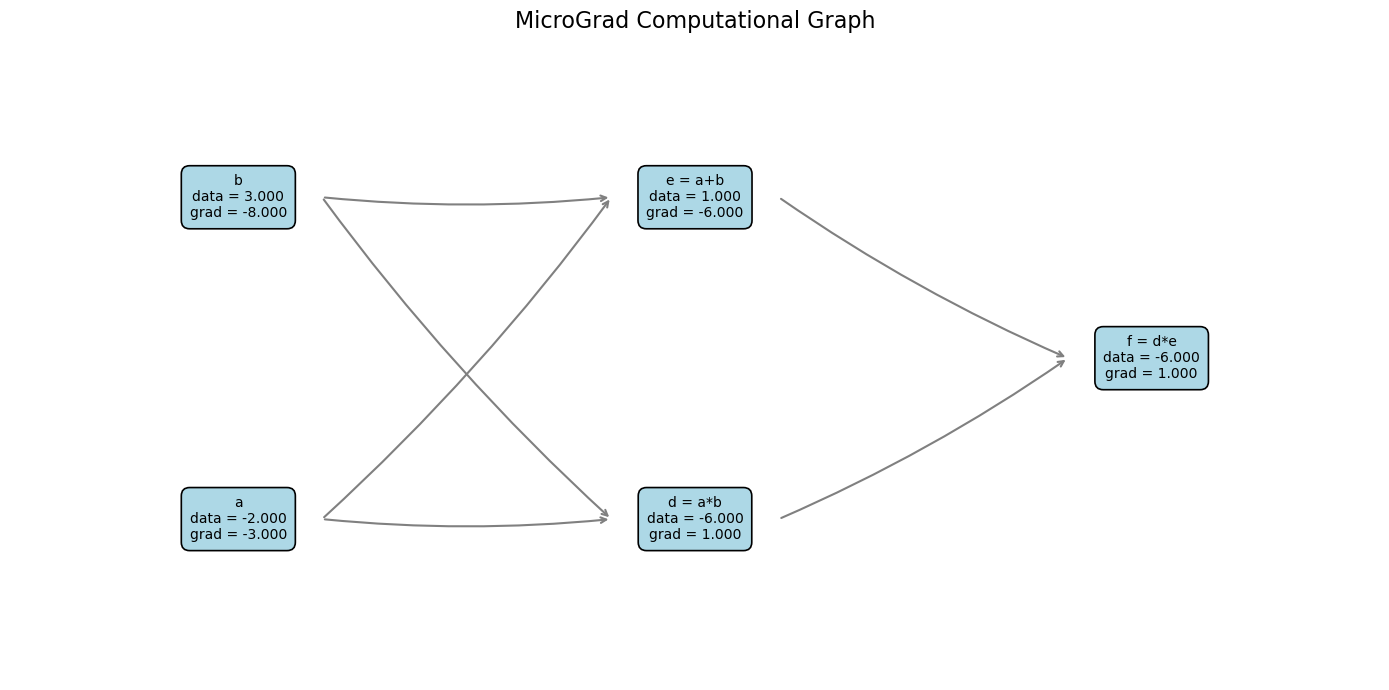

In [10]:

def draw_computational_graph(root):
    nodes = []
    edges = []
    visited = set()

    def visit(node):
        if node in visited:
            return

        visited.add(node)
        nodes.append(node)

        for parent in node._prev:
            edges.append((parent, node))
            visit(parent)

    visit(root)

    # Calculate depth of every node
    depth = {}

    def get_depth(node):
        if node not in depth:
            if not node._prev:
                depth[node] = 0
            else:
                depth[node] = 1 + max(get_depth(p) for p in node._prev)

        return depth[node]

    for node in nodes:
        get_depth(node)

    # Group nodes by depth
    levels = {}

    for node in nodes:
        levels.setdefault(depth[node], []).append(node)

    # Assign positions
    positions = {}

    for level, level_nodes in levels.items():
        count = len(level_nodes)

        for i, node in enumerate(level_nodes):
            y = (count - 1) / 2 - i
            positions[node] = (level * 3, y * 2)

    # Draw graph
    fig, ax = plt.subplots(figsize=(14, 7))

    # Draw arrows first
    for parent, child in edges:
        x1, y1 = positions[parent]
        x2, y2 = positions[child]

        ax.annotate(
            "",
            xy=(x2 - 0.55, y2),
            xytext=(x1 + 0.55, y1),
            arrowprops=dict(
                arrowstyle="->",
                color="gray",
                lw=1.5,
                connectionstyle="arc3,rad=0.05"
            )
        )

    # Draw nodes
    for node in nodes:
        x, y = positions[node]

        label = node.label if node.label else node._op or "input"

        node_text = (
            f"{label}\n"
            f"data = {node.data:.3f}\n"
            f"grad = {node.grad:.3f}"
        )

        ax.text(
            x, y,
            node_text,
            ha="center",
            va="center",
            fontsize=10,
            bbox=dict(
                boxstyle="round,pad=0.6",
                facecolor="lightblue",
                edgecolor="black",
                linewidth=1.2
            )
        )

    ax.set_title("MicroGrad Computational Graph", fontsize=16)
    ax.axis("off")

    ax.set_xlim(-1.5, max(depth.values()) * 3 + 1.5)
    ax.set_ylim(-max(len(level) for level in levels.values()), 
                max(len(level) for level in levels.values()))

    plt.tight_layout()
    plt.show()


draw_computational_graph(f)


## 6. Build a neuron, layer, and MLP

The network API is hierarchical:

- `Neuron(nin)` creates one neuron with `nin` inputs.
- `Layer(nin, nout)` creates `nout` neurons.
- `MLP(nin, nouts)` creates a sequence of layers.

The following cell checks the output shapes and number of trainable parameters.


In [6]:
neuron = Neuron(3)
neuron_output = neuron([Value(0.2), Value(-0.4), Value(0.7)])
print("Neuron output:", neuron_output.data)

layer = Layer(3, 4)
layer_output = layer([Value(0.2), Value(-0.4), Value(0.7)])
print("Layer output count:", len(layer_output))

model = MLP(3, [4, 4, 1])
model_output = model([Value(0.2), Value(-0.4), Value(0.7)])
print("MLP output:", model_output.data)
print("Number of parameters:", len(model.parameters()))

assert len(model.parameters()) == 41


Neuron output: -0.4076381078398668
Layer output count: 4
MLP output: 0.34527059537257204
Number of parameters: 41


## 7. Train a small MLP on a toy dataset

This is a small demonstration of using the autograd engine to train a neural network. The dataset is a simple two-input binary classification problem (XOR).

Training procedure:

1. Run a forward pass for each example.
2. Calculate the squared-error loss.
3. Backpropagate the loss gradients.
4. Update every parameter with gradient descent.
5. Reset gradients before the next iteration.

This is a demonstration dataset, not a required external dataset.


In [7]:
# XOR data: two inputs, one target.
X = [
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0],
]
Y = [0.0, 1.0, 1.0, 0.0]

random.seed(42)
model = MLP(2, [4, 4, 1])

learning_rate = 0.08
epochs = 1200
loss_history = []

for epoch in range(epochs):
    # Forward pass: one scalar prediction per example.
    predictions = [model([Value(x1), Value(x2)]) for x1, x2 in X]

    # Mean squared error (MSE).
    losses = [(prediction - target) ** 2
              for prediction, target in zip(predictions, Y)]
    loss = sum(losses, Value(0.0)) / len(losses)

    # Backward pass.
    model.zero_grad()
    loss.backward()

    # Gradient-descent parameter update.
    for parameter in model.parameters():
        parameter.data -= learning_rate * parameter.grad

    loss_history.append(loss.data)

    if epoch % 200 == 0:
        print(f"Epoch {epoch:4d} | loss = {loss.data:.6f}")

print("Final loss:", loss_history[-1])


Epoch    0 | loss = 0.568775
Epoch  200 | loss = 0.023091
Epoch  400 | loss = 0.004606
Epoch  600 | loss = 0.002316
Epoch  800 | loss = 0.001506
Epoch 1000 | loss = 0.001103
Final loss: 0.000865352479540496


## 8. Plot the training loss

A decreasing loss indicates that the model is reducing its prediction error on the training examples.


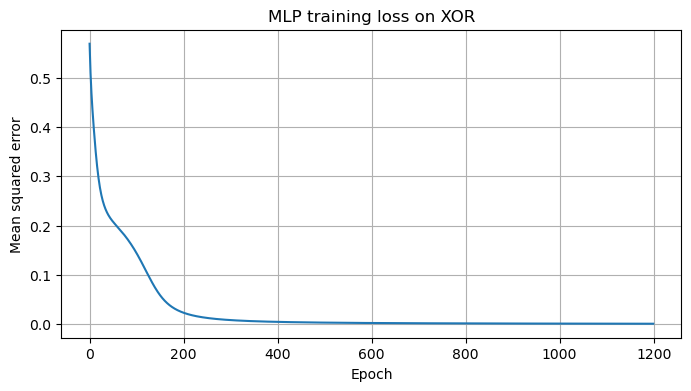

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("MLP training loss on XOR")
plt.grid(True)
plt.show()


## 9. Inspect final predictions

The output neuron uses `tanh`, so its output is between -1 and 1. For this demonstration, values closer to 1 indicate class 1 and values closer to -1 indicate class 0. The targets used above are 0 and 1, so this is a simple regression-style demonstration of XOR rather than an ideal binary-classification target encoding.


In [9]:
print("Input       Target     Prediction")
for x, target in zip(X, Y):
    prediction = model([Value(x[0]), Value(x[1])])
    print(f"{x!s:12} {target:6.1f}     {prediction.data: .4f}")


Input       Target     Prediction
[0.0, 0.0]      0.0      0.0013
[0.0, 1.0]      1.0      0.9577
[1.0, 0.0]      1.0      0.9592
[1.0, 1.0]      0.0      0.0021


## 10. Summary

In this notebook, we:

- Created scalar values and performed arithmetic operations.
- Evaluated `tanh` and `exp`.
- Used `backward()` to calculate gradients through a computational graph.
- Visualized the computational graph.
- Constructed a neuron, layer, and multilayer perceptron.
- Trained a small MLP with gradient descent and plotted its loss.

**Reproducibility note:** The random seed is fixed for the demonstrations. Training results can still depend on implementation details and numerical behavior.
